# Connecting Machine Learning to Drug discovery (PPARγ QSAR)

A complete, self-contained, pedagogically-commented reproduction of
*"Predictive modelling of PPARγ IC50 inhibition by emerging pollutants using LightGBM"*
(Awomuti et al., 2025), extended for classroom use.

### What it covers, in order
- **Part 1** — Setup & load the ChEMBL dataset
- **Part 2** — Clean the data & convert IC50 → pIC50
- **Part 3** — Generate **all** RDKit descriptors, then **select** which ones to study (correlation heatmap + pair plot)
- **Part 4** — Generate the real **881-bit PubChem fingerprints** (via PaDEL)
- **Part 5** — Screen the fingerprints down to the most informative bits
- **Part 6** — Train/test split
- **Part 7** — Train **10 different regression models** and compare them, exactly like the paper's Table 2
- **Part 8** — Reproduce the paper's hyperparameter validation curve (their Figure 1)
- **Part 9** — Full evaluation of the winning model (paper's Table 3 + Figure 3)
- **Part 10** — Interpret the model (feature importance + SHAP)
- **Part 11** — Save every trained model
- **Part 12** — Upload a CSV of new query compounds & compute their descriptors/fingerprints
- **Part 13** — **Choose which of the 10 trained models to use** for prediction
- **Part 14** — Generate & save final IC50 predictions

**Before running:** upload `QSAR_data.csv` (training data) and `query_compounds.csv`
(the compounds you want predictions for) to this Colab session's file area.


## Part 1 - Setup & Load the Dataset
## Step 1 — Import Base Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Base libraries imported.")


Base libraries imported.


## Step 2 — Upload & Load the Training Dataset

Upload `QSAR_data.csv` via the Colab Files pane, or run the upload widget below.


In [ ]:
from google.colab import files
uploaded = files.upload()

DATA_PATH = "QSAR_data.csv"
df_raw = pd.read_csv(DATA_PATH)

print(f"Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()

Saving QSAR_data.csv to QSAR_data.csv
Shape: 1868 rows, 5 columns


,ChEMBL_ID,Smiles,Standard_Type,Standard_Value,Standard_Units
0,CHEMBL3695832,CC[C@@H](NC(=O)c1ccc2c(c1)c(C)c(C)n2Cc1ccc(-c2...,IC50,0.13,nM
1,CHEMBL5191837,Cc1cncc(-c2nc3cc(NC(=O)c4cc([N+](=O)[O-])ccc4C...,IC50,0.16,nM
2,CHEMBL5207130,CCc1ccc(-c2nc3cc(NC(=O)c4cc([N+](=O)[O-])ccc4C...,IC50,0.17,nM
3,CHEMBL3678128,Cc1c(C)n(Cc2ccc(Cl)c(O[C@@H](C)C(=O)O)c2)c2ccc...,IC50,0.20,nM
4,CHEMBL5187164,CCc1ccc(-c2nc3cc(NC(=O)c4cc([N+](=O)[O-])ccc4B...,IC50,0.22,nM


---
# Part 2 — Clean the Data & Convert IC50 → pIC50

Same reasoning as before: keep valid IC50/nM rows only, recognize duplicate compounds
via canonical SMILES, average their pIC50, and transform IC50 (nM) into the more
model-friendly pIC50 scale.

## Step 3 — Install RDKit

In [ ]:
!pip install rdkit -q

from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

print("RDKit ready.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 41.4 MB/s eta 0:00:00
RDKit ready.


## Step 4 — Filter, Canonicalize, Convert, De-duplicate

In [ ]:
# Keep only valid IC50/nM measurements
df = df_raw[(df_raw['Standard_Type'] == 'IC50') & (df_raw['Standard_Units'] == 'nM')].copy()
df = df.dropna(subset=['Standard_Value', 'Smiles'])
df = df[df['Standard_Value'] > 0]

# Canonicalize SMILES so the same molecule is recognized regardless of how it was written
def canonicalize(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol) if mol is not None else None

df['Canonical_Smiles'] = df['Smiles'].apply(canonicalize)
df = df.dropna(subset=['Canonical_Smiles'])

# Convert IC50 (nM) -> pIC50
df['pIC50'] = 9 - np.log10(df['Standard_Value'])

# Average pIC50 for compounds measured more than once
df_clean = (
    df.groupby('Canonical_Smiles', as_index=False)
      .agg(Compound_ID=('ChEMBL_ID', 'first'), pIC50=('pIC50', 'mean'))
      .rename(columns={'Canonical_Smiles': 'Smiles'})
)

print(f"Unique compounds after cleaning: {len(df_clean)}")
df_clean.head()


Unique compounds after cleaning: 1522


,Smiles,Compound_ID,pIC50
0,C#CCOC(=O)N1CCc2c(OCCc3nc(-c4ccccc4)oc3C)ccc(C...,CHEMBL223434,7.619789
1,C#CCOc1cccc(Cc2c(C)n(C(=O)c3ccc(OC)cc3)c3ccc(O...,CHEMBL372913,7.207608
2,C/C(=N/OCCOc1cccc(CC2SC(=O)NC2=O)c1)c1ccc(-c2c...,CHEMBL3585578,6.721246
3,C/C(CC(=O)Nc1ccc(C)cc1C)=N\NC(=N)N,CHEMBL4852057,3.744727
4,C/C=C(\C)C(=O)OC[C@@]12C(=O)C[C@@H](C)[C@](C)(...,CHEMBL5590953,5.899629


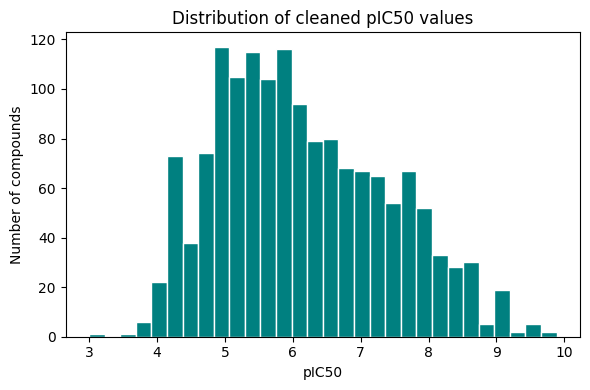

Saved: pIC50_distribution.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(df_clean['pIC50'], bins=30, color='teal', edgecolor='white')
plt.xlabel('pIC50')
plt.ylabel('Number of compounds')
plt.title('Distribution of cleaned pIC50 values')
plt.tight_layout()
plt.savefig('pIC50_distribution.pdf')
plt.show()

print("Saved: pIC50_distribution.pdf")

from google.colab import files
files.download('pIC50_distribution.pdf')

---
# Part 3 — Generating Descriptors using RDKit

## Step 5 — Compute *Every* RDKit Descriptor for Every Compound

`Descriptors._descList` is RDKit's internal registry of every descriptor it knows how to
calculate, paired with the function that calculates it. We loop over all of them for
every compound.


In [ ]:
def calculate_all_rdkit_descriptors(smiles):
    """
    Compute EVERY descriptor in RDKit's registry for one SMILES string.
    Returns a dict: {descriptor_name: value}. NaN values mean that particular
    descriptor's calculation failed for this molecule (rare, but happens for a
    handful of descriptors on unusual structures).
    """
    mol = Chem.MolFromSmiles(smiles)
    descriptor_names = [name for name, _ in Descriptors._descList]
    if mol is None:
        return {name: np.nan for name in descriptor_names}

    values = {}
    for name, func in Descriptors._descList:
        try:
            values[name] = func(mol)
        except Exception:
            values[name] = np.nan
    return values


# Test on one molecule first (DMSO) before running it on everything
test_result = calculate_all_rdkit_descriptors('CS(=O)C')
print(f"RDKit computed {len(test_result)} descriptors for DMSO. A few examples:")
{k: test_result[k] for k in list(test_result)[:6]}


RDKit computed 217 descriptors for DMSO. A few examples:


{'MaxAbsEStateIndex': np.float64(9.555555555555555),
 'MaxEStateIndex': np.float64(9.555555555555555),
 'MinAbsEStateIndex': np.float64(0.6111111111111112),
 'MinEStateIndex': np.float64(-0.6111111111111112),
 'qed': 0.39818507746332077,
 'SPS': 8.75}

In [ ]:
# Run it on every cleaned compound
all_descriptor_rows = df_clean['Smiles'].apply(calculate_all_rdkit_descriptors)
all_descriptors_df = pd.DataFrame(all_descriptor_rows.tolist())

all_descriptors_df.insert(0, 'Smiles', df_clean['Smiles'].values)
all_descriptors_df.insert(0, 'Compound_ID', df_clean['Compound_ID'].values)
all_descriptors_df['pIC50'] = df_clean['pIC50'].values

print(f"Computed {all_descriptors_df.shape[1] - 3} descriptors for {len(all_descriptors_df)} compounds.")
all_descriptors_df.head()


Computed 217 descriptors for 1522 compounds.


,Compound_ID,Smiles,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,pIC50
0,CHEMBL223434,C#CCOC(=O)N1CCc2c(OCCc3nc(-c4ccccc4)oc3C)ccc(C...,12.361380,12.361380,0.003340,-0.872198,0.445064,12.500000,488.540,460.316,...,0,0,1,0,0,0,0,0,0,7.619789
1,CHEMBL372913,C#CCOc1cccc(Cc2c(C)n(C(=O)c3ccc(OC)cc3)c3ccc(O...,13.504712,13.504712,0.107433,-4.840216,0.290024,11.222222,493.481,471.305,...,0,0,1,0,0,0,0,0,0,7.207608
2,CHEMBL3585578,C/C(=N/OCCOc1cccc(CC2SC(=O)NC2=O)c1)c1ccc(-c2c...,11.744116,11.744116,0.242909,-0.393376,0.274159,15.909091,460.555,436.363,...,0,0,0,0,0,0,0,0,0,6.721246
3,CHEMBL4852057,C/C(CC(=O)Nc1ccc(C)cc1C)=N\NC(=N)N,11.800048,11.800048,0.146425,-0.255429,0.374801,11.000000,261.329,242.177,...,0,0,0,0,0,0,0,0,0,3.744727
4,CHEMBL5590953,C/C=C(\C)C(=O)OC[C@@]12C(=O)C[C@@H](C)[C@](C)(...,13.677994,13.677994,0.069584,-1.438718,0.344419,37.562500,467.002,431.722,...,0,0,0,0,0,0,0,0,0,5.899629


## Step 6 — Drop Descriptors That Are Useless by Construction

Some descriptors will be constant across every compound in our dataset, or fail
entirely (all NaN) — these carry zero information and would break later steps like
correlation calculations, so we drop them now, before doing anything else with them.


In [ ]:
descriptor_cols_all = [c for c in all_descriptors_df.columns if c not in ('Compound_ID', 'Smiles', 'pIC50')]

nunique = all_descriptors_df[descriptor_cols_all].nunique(dropna=True)
constant_cols = nunique[nunique <= 1].index.tolist()
all_nan_cols = all_descriptors_df[descriptor_cols_all].columns[
    all_descriptors_df[descriptor_cols_all].isna().all()
].tolist()
cols_to_drop = list(set(constant_cols + all_nan_cols))

all_descriptors_df = all_descriptors_df.drop(columns=cols_to_drop)
descriptor_cols_all = [c for c in all_descriptors_df.columns if c not in ('Compound_ID', 'Smiles', 'pIC50')]

# Fill any remaining rare, isolated NaNs with the column median
all_descriptors_df[descriptor_cols_all] = all_descriptors_df[descriptor_cols_all].fillna(
    all_descriptors_df[descriptor_cols_all].median()
)

print(f"Dropped {len(cols_to_drop)} constant/empty descriptors.")
print(f"Usable descriptor pool: {len(descriptor_cols_all)} descriptors.")

all_descriptors_df.to_csv('compound_all_descriptors.csv', index=False)
print("Saved: compound_all_descriptors.csv  (the FULL descriptor table)")

from google.colab import files
files.download('compound_all_descriptors.csv')


Dropped 15 constant/empty descriptors.
Usable descriptor pool: 202 descriptors.
Saved: compound_all_descriptors.csv  (the FULL descriptor table)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 7 — CHOOSE Your Descriptors of Interest

**This is the cell to edit.** `SELECTED_DESCRIPTORS` below defaults to the exact 7
Lipinski-type descriptors the reference paper studied — but you (or your students) can
freely add or remove names from this list to explore *any* of the 200+ descriptors
computed in Step 5.

Run `all_descriptors_df.columns.tolist()` in a scratch cell any time to see every
available option.


In [ ]:
# ============================================================
# STUDENTS: EDIT THIS LIST TO CHOOSE WHICH DESCRIPTORS TO STUDY
# ============================================================
# Defaults to the paper's own descriptor choices (RDKit's internal names on the left,
# the friendlier name we'll display them as on the right):
SELECTED_DESCRIPTORS = {
    'MolWt': 'MW',
    'MolLogP': 'LogP',
    'NumHDonors': 'NumHDonors',
    'NumHAcceptors': 'NumHAcceptors',
    'NumRotatableBonds': 'NumRotatableBonds',
    'RingCount': 'NumRings',
    'LabuteASA': 'MolSurfaceArea',
}
# Example of trying something different -- uncomment to experiment:
# SELECTED_DESCRIPTORS['TPSA'] = 'TPSA'
# SELECTED_DESCRIPTORS['NumAromaticRings'] = 'NumAromaticRings'

selected_descriptors_df = all_descriptors_df[
    ['Compound_ID', 'Smiles'] + list(SELECTED_DESCRIPTORS.keys()) + ['pIC50']
].rename(columns=SELECTED_DESCRIPTORS)

print(f"Selected {len(SELECTED_DESCRIPTORS)} descriptors for detailed study:")
print(list(SELECTED_DESCRIPTORS.values()))
selected_descriptors_df.head()


Selected 7 descriptors for detailed study:
['MW', 'LogP', 'NumHDonors', 'NumHAcceptors', 'NumRotatableBonds', 'NumRings', 'MolSurfaceArea']


,Compound_ID,Smiles,MW,LogP,NumHDonors,NumHAcceptors,NumRotatableBonds,NumRings,MolSurfaceArea,pIC50
0,CHEMBL223434,C#CCOC(=O)N1CCc2c(OCCc3nc(-c4ccccc4)oc3C)ccc(C...,488.540,4.41662,1,6,9,4,209.401413,7.619789
1,CHEMBL372913,C#CCOc1cccc(Cc2c(C)n(C(=O)c3ccc(OC)cc3)c3ccc(O...,493.481,6.14822,0,4,7,4,205.563914,7.207608
2,CHEMBL3585578,C/C(=N/OCCOc1cccc(CC2SC(=O)NC2=O)c1)c1ccc(-c2c...,460.555,5.06730,1,6,9,4,196.531765,6.721246
3,CHEMBL4852057,C/C(CC(=O)Nc1ccc(C)cc1C)=N\NC(=N)N,261.329,1.49101,4,3,4,1,112.137945,3.744727
4,CHEMBL5590953,C/C=C(\C)C(=O)OC[C@@]12C(=O)C[C@@H](C)[C@](C)(...,467.002,4.13080,1,6,7,3,194.910319,5.899629


## Step 8 — Save the Selected Descriptor Table


In [ ]:
selected_descriptors_df.to_csv('compound_descriptors_selected.csv', index=False)
print("Saved: compound_descriptors_selected.csv")

from google.colab import files
files.download('compound_descriptors_selected.csv')


Saved: compound_descriptors_selected.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 9 — Correlation Heatmap

Exactly the same analysis the paper performs — but on whichever descriptors *you*
selected in Step 7.


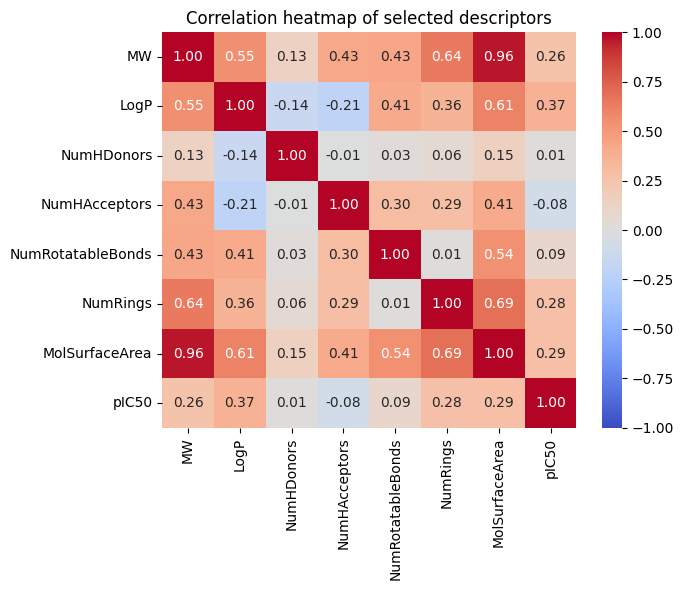

In [ ]:
plt.figure(figsize=(7, 6))
corr = selected_descriptors_df.drop(columns=['Compound_ID', 'Smiles']).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation heatmap of selected descriptors')
plt.tight_layout()
plt.show()





## Step 10 — Pair Plot (A Second View of the Same Relationships)

The paper also uses pair plots (their Figures 5–6) to visualize relationships between
variables. A pair plot shows every descriptor plotted against every other descriptor
(scatterplots) plus each one's own distribution (histograms on the diagonal) — a more
detailed complement to the correlation heatmap above.


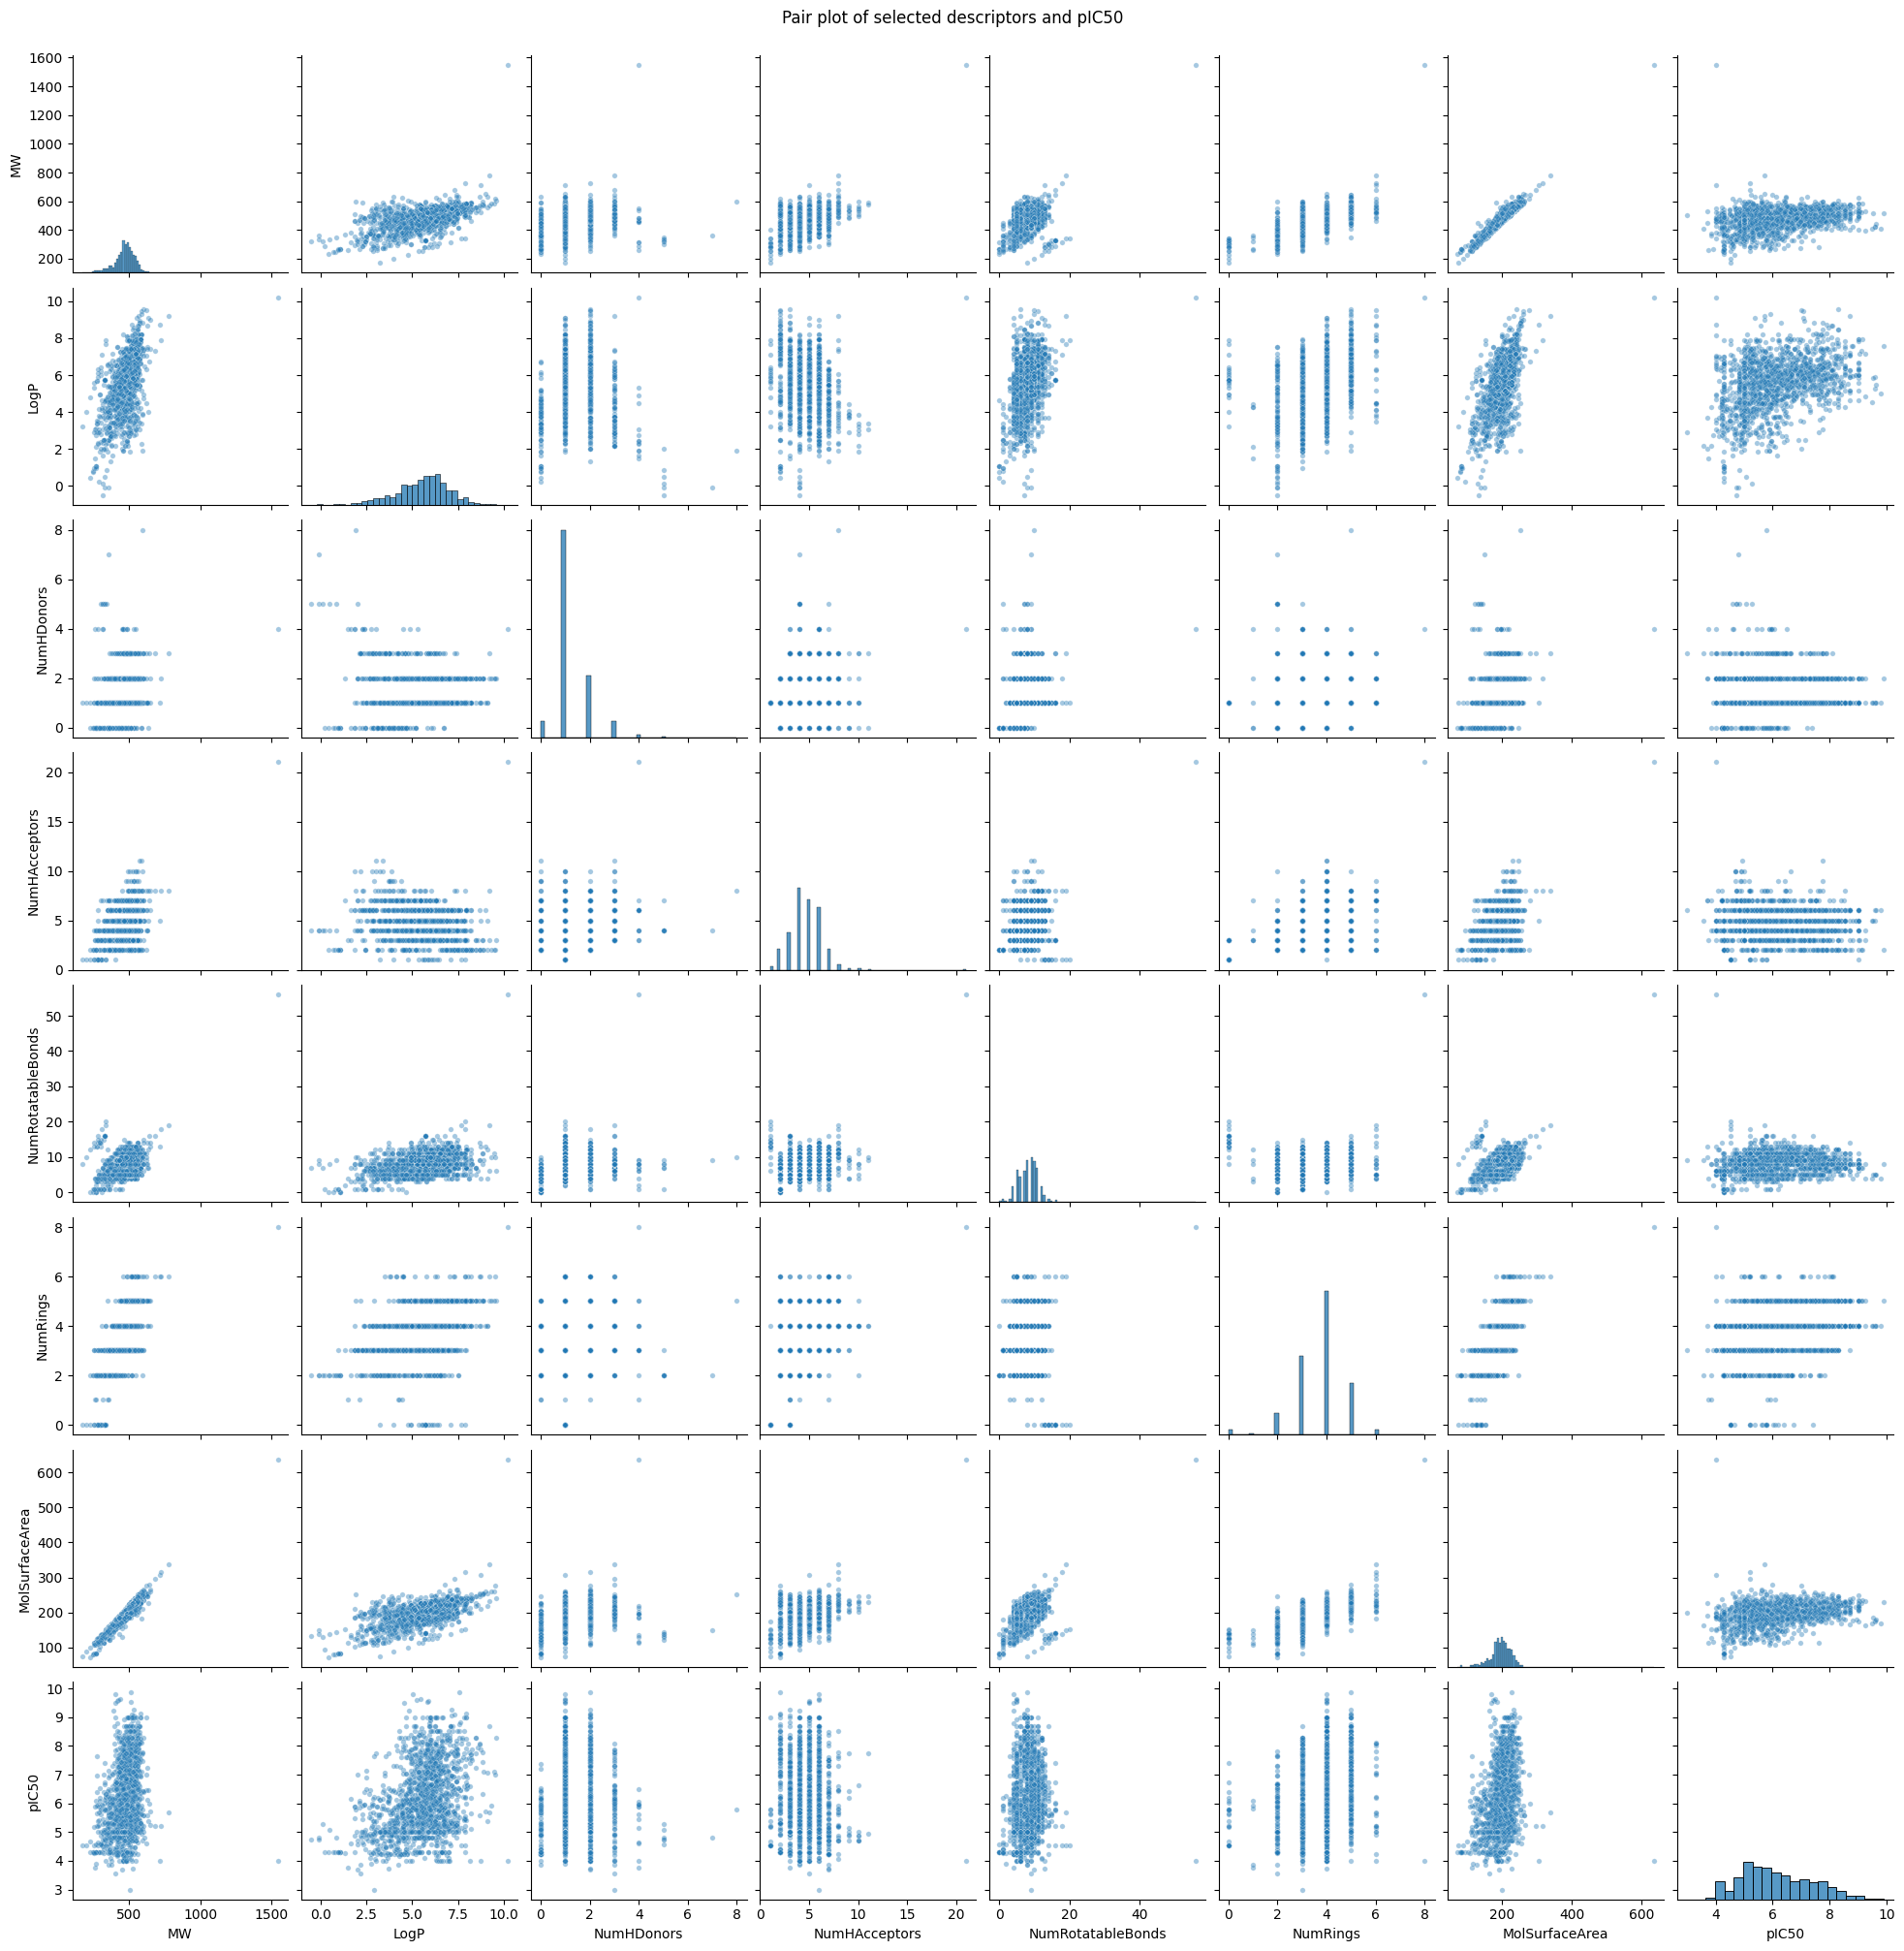

In [ ]:
sns.pairplot(selected_descriptors_df.drop(columns=['Compound_ID', 'Smiles']),
             diag_kind='hist', plot_kws={'alpha': 0.4, 's': 15})
plt.suptitle('Pair plot of selected descriptors and pIC50', y=1.01)
plt.show()


---
# Part 4 — Generate the Real PubChem Fingerprints

## Step 11 — Set Up PaDEL-Descriptor

In [ ]:
!apt-get update -qq
!apt-get install -y default-jre -qq
!java -version

!pip install padelpy -q

# Download the PubChem fingerprint "recipe" XML file
!wget https://github.com/dataprofessor/padel/raw/main/fingerprints_xml.zip
!unzip -o fingerprints_xml.zip

!ls *.xml


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package at-spi2-common.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../00-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../01-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../02-libxtst6_2%3a1.2.3-1.1build1_amd64.deb ...
Unpacking libxtst6:amd64 (2:1.2.3-1.1build1) ...
Selecting previously unselected package session-migration.
Preparing to unpack .../03-session-migration_0.3.9build1_amd64.deb ...
Unpacking session-migration (0.3.9build1) ...
Selecting previously unse

## Step 12 — Write the PaDEL Input File & Run It

In [ ]:
with open('molecule.smi', 'w') as f:
    for smi, cid in zip(df_clean['Smiles'], df_clean['Compound_ID']):
        f.write(f"{smi}\t{cid}\n")

print(f"Wrote {len(df_clean)} molecules to molecule.smi")


Wrote 1522 molecules to molecule.smi


In [ ]:
from padelpy import padeldescriptor

padeldescriptor(
    mol_dir='molecule.smi',
    d_file='descriptors_output.csv',
    descriptortypes='PubchemFingerprinter.xml',
    fingerprints=True,
    detectaromaticity=True,
    standardizenitro=True,
    standardizetautomers=True,
    removesalt=True,
    log=True,
)

print("PaDEL finished.")


PaDEL finished.


## Step 13 — Load, Inspect, and Save the Fingerprints

In [ ]:
fingerprints_df = pd.read_csv('descriptors_output.csv').rename(columns={'Name': 'Compound_ID'})

print(f"Fingerprint table shape: {fingerprints_df.shape}")
fingerprints_df.head()


Fingerprint table shape: (1522, 882)


,Compound_ID,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,...,PubchemFP871,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880
0,CHEMBL223434,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,CHEMBL372913,1,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,CHEMBL3585578,1,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,CHEMBL4852057,1,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,CHEMBL5590953,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Look at one compound's actual "on" bits, same as before
example_id = fingerprints_df['Compound_ID'].iloc[0]
example_row = fingerprints_df[fingerprints_df['Compound_ID'] == example_id].iloc[0]
fp_columns = [c for c in fingerprints_df.columns if c != 'Compound_ID']
on_bits = example_row[fp_columns]
on_bits = on_bits[on_bits == 1]

print(f"Compound {example_id}: {len(on_bits)} of {len(fp_columns)} bits are ON")
on_bits


Compound CHEMBL223434: 204 of 881 bits are ON


,0
PubchemFP9,1
PubchemFP10,1
PubchemFP11,1
PubchemFP12,1
PubchemFP14,1
...,...
PubchemFP777,1
PubchemFP797,1
PubchemFP798,1
PubchemFP818,1


In [ ]:
fingerprints_df.to_csv('compound_pubchem_fingerprints.csv', index=False)
print("Saved: compound_pubchem_fingerprints.csv")

from google.colab import files
files.download('compound_pubchem_fingerprints.csv')


Saved: compound_pubchem_fingerprints.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Part 5 — Screen the Fingerprints

Same two-stage screening as before: drop near-constant bits, then rank and keep the
most informative survivors.

## Step 14 — Merge Fingerprints With pIC50, Drop Near-Constant Bits

In [ ]:
from sklearn.feature_selection import VarianceThreshold

model_data = fingerprints_df.merge(df_clean[['Compound_ID', 'pIC50']], on='Compound_ID', how='inner')
fp_cols_all = [c for c in fingerprints_df.columns if c != 'Compound_ID']

X_all_fp = model_data[fp_cols_all]
selector = VarianceThreshold(threshold=0.01 * (1 - 0.01))
selector.fit(X_all_fp)
fp_cols_variant = X_all_fp.columns[selector.get_support()].tolist()

print(f"Bits before filtering: {len(fp_cols_all)}  |  Bits after filtering: {len(fp_cols_variant)}")


Bits before filtering: 881  |  Bits after filtering: 443


## Step 15 — Rank & Select the Top Fingerprint Bits

In [ ]:
from sklearn.ensemble import RandomForestRegressor

def select_important_features(X, y, top_n=100, random_state=RANDOM_STATE):
    """Rank features by Random Forest importance and return the top N."""
    ranker = RandomForestRegressor(n_estimators=300, random_state=random_state, n_jobs=-1)
    ranker.fit(X, y)
    ranking_df = (
        pd.DataFrame({'feature': X.columns, 'importance': ranker.feature_importances_})
        .sort_values('importance', ascending=False)
        .reset_index(drop=True)
    )
    return ranking_df, ranking_df.head(top_n)['feature'].tolist()


FP_TOP_N = 100   # tunable -- try 50 or 200 and re-run Parts 6-9 to compare

y = model_data['pIC50']
fp_ranking_df, selected_fp_cols = select_important_features(model_data[fp_cols_variant], y, top_n=FP_TOP_N)

print(f"Selected top {FP_TOP_N} fingerprint bits.")
fp_ranking_df.head(15)


Selected top 100 fingerprint bits.


,feature,importance
0,PubchemFP397,0.057512
1,PubchemFP597,0.054803
2,PubchemFP192,0.041703
3,PubchemFP663,0.027682
4,PubchemFP261,0.025309
5,PubchemFP374,0.023472
6,PubchemFP339,0.020702
7,PubchemFP259,0.019875
8,PubchemFP497,0.019381
9,PubchemFP707,0.018714


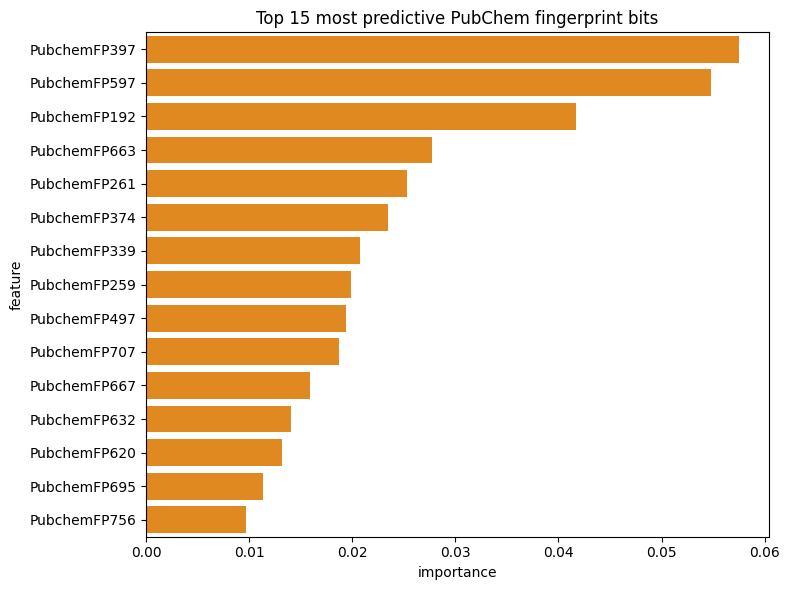

Saved: selected_fingerprints.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(8, 6))
sns.barplot(data=fp_ranking_df.head(15), x='importance', y='feature', color='darkorange')
plt.title('Top 15 most predictive PubChem fingerprint bits')
plt.tight_layout()
plt.show()

selected_fp_df = model_data[['Compound_ID'] + selected_fp_cols + ['pIC50']]
selected_fp_df.to_csv('selected_fingerprints.csv', index=False)
print("Saved: selected_fingerprints.csv")

from google.colab import files
files.download('selected_fingerprints.csv')


---
# Part 6 — Train/Test Split (80/20, Matching the Paper)


In [ ]:
from sklearn.model_selection import train_test_split

X = model_data[selected_fp_cols]
y = model_data['pIC50']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)

print(f"Training set: {X_train.shape[0]} compounds")
print(f"Test set:     {X_test.shape[0]} compounds")


Training set: 1217 compounds
Test set:     305 compounds


---
# Part 7 — Train 10 Regression Models & Compare Them


## Step 16 — Install the Extra Libraries We Need

In [ ]:
!pip install lightgbm xgboost -q

import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                               ExtraTreesRegressor, AdaBoostRegressor)
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Modelling libraries ready.")


Modelling libraries ready.


## Step 17 — Define All 10 Models

Each one gets the exact same training data — this is what makes the comparison fair.


In [ ]:
models_to_train = {
    'LightGBM':         lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=RANDOM_STATE),
    'XGBoost':          xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=RANDOM_STATE, verbosity=0),
    'RandomForest':     RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE),
    'ExtraTrees':       ExtraTreesRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'AdaBoost':         AdaBoostRegressor(n_estimators=100, random_state=RANDOM_STATE),
    'DecisionTree':     DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    'KNeighbors':       KNeighborsRegressor(n_neighbors=5),
    'Ridge':            Ridge(alpha=1.0),
    'LinearRegression': LinearRegression(),
}

print(f"Defined {len(models_to_train)} models: {list(models_to_train.keys())}")


Defined 10 models: ['LightGBM', 'XGBoost', 'RandomForest', 'GradientBoosting', 'ExtraTrees', 'AdaBoost', 'DecisionTree', 'KNeighbors', 'Ridge', 'LinearRegression']


## Step 18 — Train Every Model & Evaluate All of Them the Same Way


In [ ]:
trained_models = {}
comparison_rows = []

for name, model in models_to_train.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    row = {'Model': name}
    for split_name, X_split, y_split in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        y_pred = model.predict(X_split)
        row[f'{split_name}_R2'] = r2_score(y_split, y_pred)
        row[f'{split_name}_MAE'] = mean_absolute_error(y_split, y_pred)
        row[f'{split_name}_RMSE'] = np.sqrt(mean_squared_error(y_split, y_pred))
    comparison_rows.append(row)
    print(f"Trained: {name}")

model_comparison_df = pd.DataFrame(comparison_rows).sort_values('Test_R2', ascending=False).reset_index(drop=True)
print("\nAll models trained. Comparison (sorted by Test R2, best first):")
model_comparison_df.round(4)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002065 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 200
[LightGBM] [Info] Number of data points in the train set: 1217, number of used features: 100
[LightGBM] [Info] Start training from score 6.146364
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

,Model,Train_R2,Train_MAE,Train_RMSE,Test_R2,Test_MAE,Test_RMSE
0,LightGBM,0.8251,0.3786,0.5161,0.6210,0.5571,0.7938
1,GradientBoosting,0.7081,0.5071,0.6668,0.6062,0.6077,0.8091
2,KNeighbors,0.7412,0.4312,0.6278,0.5933,0.5758,0.8223
3,RandomForest,0.9154,0.2405,0.3589,0.5836,0.5733,0.8320
4,XGBoost,0.9096,0.2500,0.3710,0.5761,0.5754,0.8394
5,Ridge,0.5513,0.6526,0.8267,0.5101,0.6938,0.9024
6,LinearRegression,0.5551,0.6492,0.8232,0.4739,0.7018,0.9352
7,DecisionTree,0.7445,0.4207,0.6238,0.4076,0.6715,0.9924
8,AdaBoost,0.4466,0.7719,0.9181,0.3861,0.8468,1.0102
9,ExtraTrees,0.9558,0.0954,0.2594,0.3479,0.6700,1.0412


## Step 19 — Visualize the Comparison


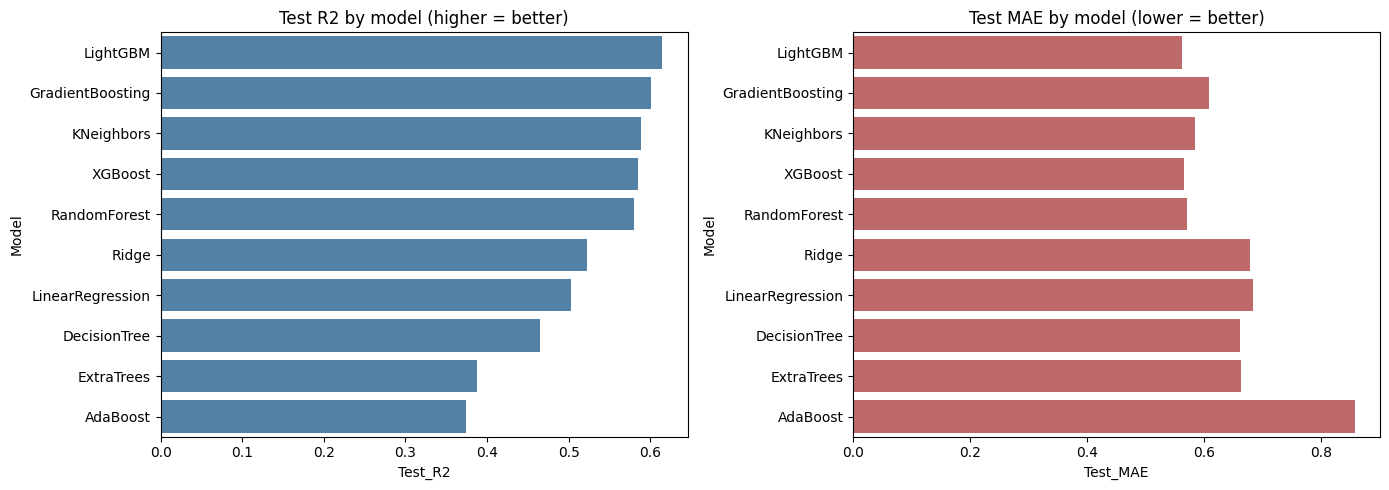

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=model_comparison_df, x='Test_R2', y='Model', ax=axes[0], color='steelblue')
axes[0].set_title('Test R2 by model (higher = better)')

sns.barplot(data=model_comparison_df, x='Test_MAE', y='Model', ax=axes[1], color='indianred')
axes[1].set_title('Test MAE by model (lower = better)')

plt.tight_layout()
plt.show()


## Step 20 — Identify the Best Model

We pick the model with the highest **Test R²** — this matters more than Train R², since
test performance is what tells us how well the model generalizes to compounds it
hasn't seen (which is the entire point of a QSAR model).


In [ ]:
BEST_MODEL_NAME = model_comparison_df.iloc[0]['Model']
best_model = trained_models[BEST_MODEL_NAME]

print(f"Best-performing model on the test set: {BEST_MODEL_NAME}")
print(f"Test R2 = {model_comparison_df.iloc[0]['Test_R2']:.4f}")


Best-performing model on the test set: LightGBM
Test R2 = 0.6210


---
# Part 8 — Hyperparameter Validation Curve

The paper specifically tunes LightGBM's `max_depth` using a validation curve — plotting
training score and cross-validation score as `max_depth` increases, to find the point
where the model stops generalizing better and starts just memorizing. We reproduce that
exact analysis here, regardless of which model won Part 7, since it's illustrating a
general tuning *technique*, not just this one dataset's specific winner.


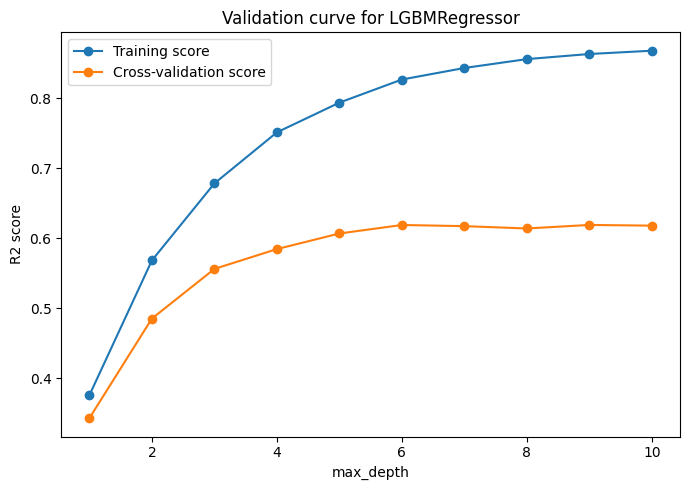

In [ ]:
from sklearn.model_selection import validation_curve

depth_range = list(range(1, 11))
train_scores, val_scores = validation_curve(
    lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE),
    X_train, y_train,
    param_name='max_depth', param_range=depth_range,
    cv=5, scoring='r2', n_jobs=-1,
)

plt.figure(figsize=(7, 5))
plt.plot(depth_range, train_scores.mean(axis=1), marker='o', label='Training score')
plt.plot(depth_range, val_scores.mean(axis=1), marker='o', label='Cross-validation score')
plt.xlabel('max_depth')
plt.ylabel('R2 score')
plt.title('Validation curve for LGBMRegressor')
plt.legend()
plt.tight_layout()
plt.show()


---
# Part 9 — Full Evaluation of the Best Model

Now the detailed metrics and plots, applied to whichever model Part 7 crowned the
winner (`best_model` / `BEST_MODEL_NAME`).

## Step 21 — Compute the Paper's Exact Metrics

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

def evaluate_model(model, X_train, y_train, X_test, y_test):
    """Compute R2, MAE, MSE, RMSE, RMSLE and MAPE for train & test sets."""
    def rmsle(y_true, y_pred):
        y_pred_c = np.clip(y_pred, 0, None)
        y_true_c = np.clip(y_true, 0, None)
        return np.sqrt(np.mean((np.log1p(y_pred_c) - np.log1p(y_true_c)) ** 2))

    results = {}
    for split_name, X_split, y_split in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        y_pred = model.predict(X_split)
        results[split_name] = {
            'R2': r2_score(y_split, y_pred),
            'MAE': mean_absolute_error(y_split, y_pred),
            'MSE': mean_squared_error(y_split, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_split, y_pred)),
            'RMSLE': rmsle(y_split, y_pred),
            'MAPE': mean_absolute_percentage_error(y_split, y_pred),
        }
    return pd.DataFrame(results).round(4)


metrics_df = evaluate_model(best_model, X_train, y_train, X_test, y_test)
print(f"Performance of best model ({BEST_MODEL_NAME}):")
metrics_df


Performance of best model (LightGBM):


,Train,Test
R2,0.8251,0.6210
MAE,0.3786,0.5571
MSE,0.2663,0.6301
RMSE,0.5161,0.7938
RMSLE,0.0723,0.1089
MAPE,0.0633,0.0923


## Step 22 — Predicted vs Actual

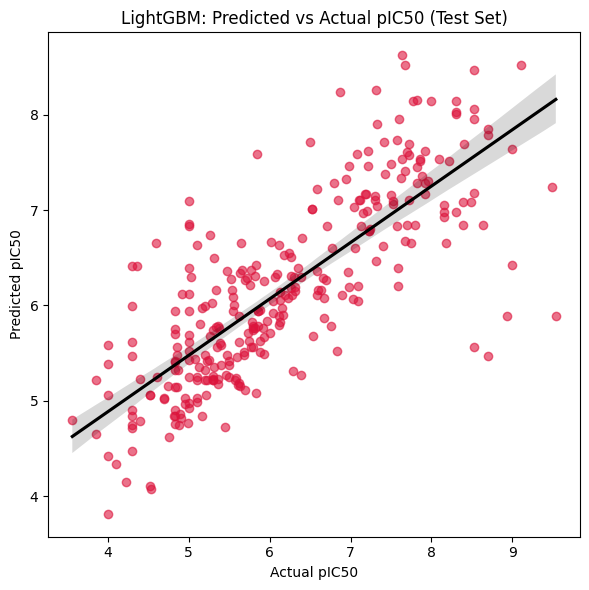

In [ ]:
y_pred_test = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
sns.regplot(x=y_test, y=y_pred_test, scatter_kws={'alpha': 0.6, 'color': 'crimson'},
            line_kws={'color': 'black'})
plt.xlabel('Actual pIC50')
plt.ylabel('Predicted pIC50')
plt.title(f'{BEST_MODEL_NAME}: Predicted vs Actual pIC50 (Test Set)')
plt.tight_layout()
plt.show()


---
# Part 10 — Interpreting the Best Model

## Step 23 — Feature Importance (Works for Any Tree-Based Model)

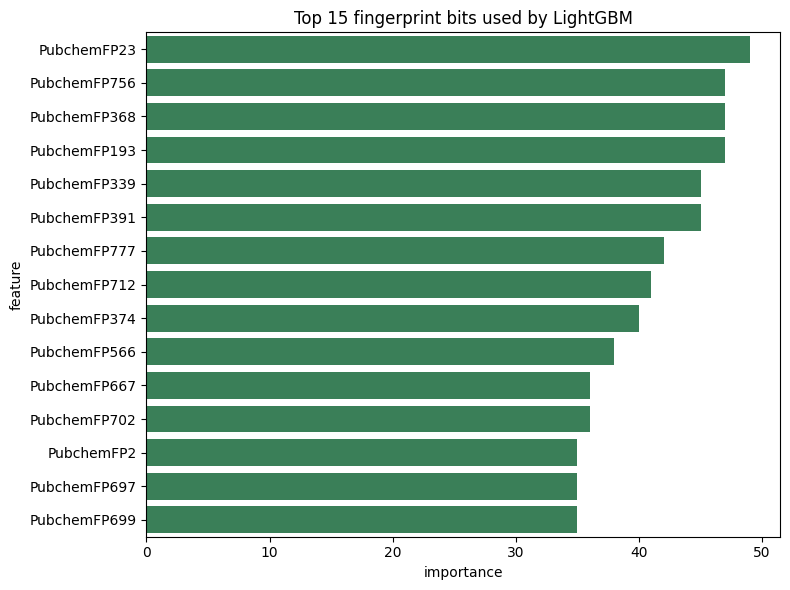

In [ ]:
if hasattr(best_model, 'feature_importances_'):
    importance_df = pd.DataFrame({
        'feature': X_train.columns,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False).head(15)

    plt.figure(figsize=(8, 6))
    sns.barplot(data=importance_df, x='importance', y='feature', color='seagreen')
    plt.title(f'Top 15 fingerprint bits used by {BEST_MODEL_NAME}')
    plt.tight_layout()
    plt.show()
else:
    print(f"{BEST_MODEL_NAME} doesn't expose feature_importances_ directly "
          f"(this happens for models like Ridge/LinearRegression/KNeighbors) -- "
          f"use the .coef_ attribute instead for linear models, or SHAP below.")


## Step 24 — SHAP Analysis (For Tree-Based Models)

`shap.TreeExplainer` works specifically for tree-based models. If the best model
happens to be a linear or distance-based model instead, we note that a different SHAP
explainer would be needed (`LinearExplainer`, `KernelExplainer`).


/tmp/ipykernel_832/896837609.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, max_display=15, show=True)


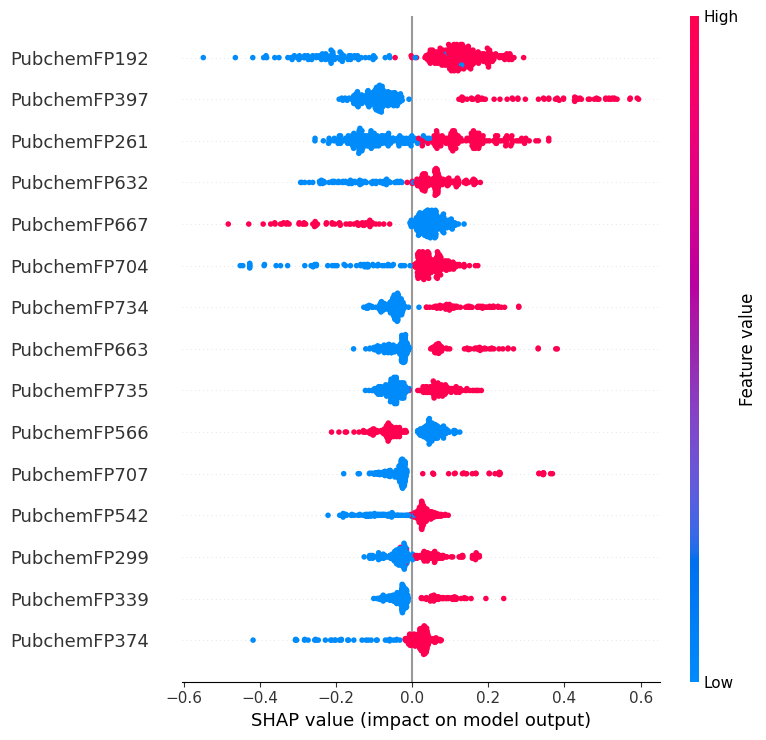

In [ ]:
!pip install shap -q
import shap

tree_based_types = (lgb.LGBMRegressor, xgb.XGBRegressor, RandomForestRegressor,
                     GradientBoostingRegressor, ExtraTreesRegressor,
                     DecisionTreeRegressor, AdaBoostRegressor)

if isinstance(best_model, tree_based_types):
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_test)
    shap.summary_plot(shap_values, X_test, max_display=15, show=True)
else:
    print(f"Best model ({BEST_MODEL_NAME}) isn't tree-based -- "
          f"shap.TreeExplainer doesn't apply. Consider shap.LinearExplainer "
          f"(for Ridge/LinearRegression) or shap.KernelExplainer (for KNeighbors) instead.")


---
# Part 11 — Save Every Trained Model

We save **all 10** models (not just the winner) — this is what makes Part 13's
"choose your own model" step possible later.


In [ ]:
import joblib

joblib.dump(trained_models, 'pparg_all_trained_models.pkl')
joblib.dump(selected_fp_cols, 'pparg_selected_fingerprint_columns.pkl')
joblib.dump(model_comparison_df, 'pparg_model_comparison.pkl')

print("Saved: pparg_all_trained_models.pkl (all 10 models)")
print("Saved: pparg_selected_fingerprint_columns.pkl")
print("Saved: pparg_model_comparison.pkl")

from google.colab import files
files.download('pparg_all_trained_models.pkl')
files.download('pparg_selected_fingerprint_columns.pkl')


Saved: pparg_all_trained_models.pkl (all 10 models)
Saved: pparg_selected_fingerprint_columns.pkl
Saved: pparg_model_comparison.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Part 12 — Predicting New Query Compounds (From an Uploaded CSV)

Instead of typing compound names/SMILES directly into the notebook, we now **upload a
CSV file** — exactly the same way you uploaded `QSAR_data.csv` at the start. This is
what makes the notebook reusable for any future set of query compounds: just prepare a
new CSV with the same 3 columns (`Compound_ID`, `Full_Name`, `Smiles`) and upload it here.

## Step 25 — Upload & Validate the Query CSV

Upload `query_compounds.csv` now via the Colab Files pane.


In [ ]:
from google.colab import files
uploaded = files.upload()

QUERY_PATH = "query_compounds.csv"
query_compounds = pd.read_csv(QUERY_PATH)

query_compounds['Valid_SMILES'] = query_compounds['Smiles'].apply(
    lambda s: Chem.MolFromSmiles(s) is not None
)

print(f"Loaded {len(query_compounds)} query compounds. All valid SMILES? "
      f"{query_compounds['Valid_SMILES'].all()}")
query_compounds


Saving query_compounds.csv to query_compounds.csv
Loaded 6 query compounds. All valid SMILES? True


,Compound_ID,Full_Name,Smiles,Valid_SMILES
0,DMSO,Dimethyl sulfoxide,CS(=O)C,True
1,DEHP,Bis(2-ethylhexyl) phthalate,CCCCC(CC)COC(=O)c1ccccc1C(=O)OCC(CC)CCCC,True
2,DIBP,Diisobutyl phthalate,CC(C)COC(=O)c1ccccc1C(=O)OCC(C)C,True
3,MEHP,Mono(2-ethylhexyl) phthalate,CCCCC(CC)COC(=O)c1ccccc1C(=O)O,True
4,MEHHP,Mono-(2-ethyl-5-hydroxyhexyl) phthalate,OC(=O)c1ccccc1C(=O)OCC(CC)CCC(O)C,True
5,MEOHP,Mono(2-ethyl-5-oxohexyl) phthalate,OC(=O)c1ccccc1C(=O)OCC(CC)CCC(=O)C,True


## Step 26 — Compute Their Descriptors (Using the Same SELECTED_DESCRIPTORS)

In [ ]:
query_all_desc_rows = query_compounds['Smiles'].apply(calculate_all_rdkit_descriptors)
query_all_descriptors_df = pd.DataFrame(query_all_desc_rows.tolist())
query_all_descriptors_df.insert(0, 'Compound_ID', query_compounds['Compound_ID'].values)

# Subset to the SAME descriptors chosen in Step 7, for a fair side-by-side comparison
query_selected_descriptors_df = query_all_descriptors_df[
    ['Compound_ID'] + list(SELECTED_DESCRIPTORS.keys())
].rename(columns=SELECTED_DESCRIPTORS)

query_selected_descriptors_df


,Compound_ID,MW,LogP,NumHDonors,NumHAcceptors,NumRotatableBonds,NumRings,MolSurfaceArea
0,DMSO,78.136,-0.0053,0,1,0,0,28.478447
1,DEHP,390.564,6.4330,0,4,14,1,170.550496
2,DIBP,278.348,3.3122,0,4,6,1,119.630959
3,MEHP,278.348,3.7580,1,3,8,1,119.311647
4,MEHHP,294.347,2.7288,2,4,8,1,124.105881
5,MEOHP,292.331,2.9370,1,4,8,1,123.473170


## Step 27 — Compute Their PubChem Fingerprints (Same PaDEL Pipeline)

In [ ]:
with open('query_molecule.smi', 'w') as f:
    for smi, cid in zip(query_compounds['Smiles'], query_compounds['Compound_ID']):
        f.write(f"{smi}\t{cid}\n")

padeldescriptor(
    mol_dir='query_molecule.smi',
    d_file='query_fingerprints.csv',
    descriptortypes='PubchemFingerprinter.xml',
    fingerprints=True,
    detectaromaticity=True,
    standardizenitro=True,
    standardizetautomers=True,
    removesalt=True,
    log=True,
)

query_fp_df = pd.read_csv('query_fingerprints.csv').rename(columns={'Name': 'Compound_ID'})

# Select the SAME fingerprint columns the models were trained on
X_query = query_fp_df.reindex(columns=selected_fp_cols, fill_value=0)

print(f"Query feature matrix: {X_query.shape[0]} compounds x {X_query.shape[1]} features")
X_query.head()


Query feature matrix: 6 compounds x 100 features


,PubchemFP397,PubchemFP597,PubchemFP192,PubchemFP663,PubchemFP261,PubchemFP374,PubchemFP339,PubchemFP259,PubchemFP497,PubchemFP707,...,PubchemFP698,PubchemFP447,PubchemFP368,PubchemFP716,PubchemFP605,PubchemFP624,PubchemFP503,PubchemFP423,PubchemFP566,PubchemFP491
0,0,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,0,1,0,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,0,1,0,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,0,1,0,0,0,1,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0


---
# Part 13 — Choose Which Trained Model to Use

This is the key step for teaching model selection: **we trained 10 models in Part 7 —
now we decide which one to actually trust for a real prediction.**

The comparison table from Step 18 is printed again below so you can make an informed
choice. By default, we go with whichever model had the best **Test R²** — the same
logic the paper itself used when it picked LightGBM out of 19 candidates — but you (or
your students) can override this and try any other model from the list.


In [ ]:
print("=== Model comparison (from Part 7), for reference ===")
print(model_comparison_df[['Model', 'Test_R2', 'Test_MAE', 'Test_RMSE']].round(4).to_string(index=False))
print()
print("Models available:", list(trained_models.keys()))


=== Model comparison (from Part 7), for reference ===
           Model  Test_R2  Test_MAE  Test_RMSE
        LightGBM   0.6210    0.5571     0.7938
GradientBoosting   0.6062    0.6077     0.8091
      KNeighbors   0.5933    0.5758     0.8223
    RandomForest   0.5836    0.5733     0.8320
         XGBoost   0.5761    0.5754     0.8394
           Ridge   0.5101    0.6938     0.9024
LinearRegression   0.4739    0.7018     0.9352
    DecisionTree   0.4076    0.6715     0.9924
        AdaBoost   0.3861    0.8468     1.0102
      ExtraTrees   0.3479    0.6700     1.0412

Models available: ['LightGBM', 'XGBoost', 'RandomForest', 'GradientBoosting', 'ExtraTrees', 'AdaBoost', 'DecisionTree', 'KNeighbors', 'Ridge', 'LinearRegression']


In [ ]:
# ============================================================
# CHOOSE WHICH MODEL TO USE FOR PREDICTION
# ============================================================
# Type the exact name of any model from the list printed above, in quotes, below.
# Defaults to the best-performing model found in Part 7 (highest Test R2).
#
# Try changing this, e.g. to 'RandomForest' or 'Ridge', and re-run Part 14 below --
# a great way to physically SEE how model choice changes real predictions.

SELECTED_MODEL_NAME = 'LightGBM'   # <-- change this string to try a different model

selected_model = trained_models[SELECTED_MODEL_NAME]

print(f"Using model: '{SELECTED_MODEL_NAME}' to predict the query compounds.")
print(f"(This model's Test R2 was "
      f"{model_comparison_df.loc[model_comparison_df['Model'] == SELECTED_MODEL_NAME, 'Test_R2'].values[0]:.4f})")


Using model: 'LightGBM' to predict the query compounds.
(This model's Test R2 was 0.6210)


---
# Part 14 — Generate & Save Final Predictions

## Step 28 — Predict pIC50, Convert to IC50 (nM), Save Results

In [ ]:
pIC50_pred = selected_model.predict(X_query)
IC50_nM_pred = 10 ** (9 - pIC50_pred)

results_df = pd.DataFrame({
    'Compound_ID': query_compounds['Compound_ID'],
    'Full_Name': query_compounds['Full_Name'],
    'Model_Used': SELECTED_MODEL_NAME,
    'Predicted_pIC50': pIC50_pred,
    'Predicted_IC50_nM': IC50_nM_pred,
}).round(3)

results_df


,Compound_ID,Full_Name,Model_Used,Predicted_pIC50,Predicted_IC50_nM
0,DMSO,Dimethyl sulfoxide,LightGBM,4.944,11381.519
1,DEHP,Bis(2-ethylhexyl) phthalate,LightGBM,5.140,7246.815
2,DIBP,Diisobutyl phthalate,LightGBM,5.144,7182.011
3,MEHP,Mono(2-ethylhexyl) phthalate,LightGBM,5.155,6998.322
4,MEHHP,Mono-(2-ethyl-5-hydroxyhexyl) phthalate,LightGBM,5.212,6141.672
5,MEOHP,Mono(2-ethyl-5-oxohexyl) phthalate,LightGBM,5.070,8503.330


In [ ]:
results_df.to_csv('query_predictions.csv', index=False)
print("Saved: query_predictions.csv")

from google.colab import files
files.download('query_predictions.csv')


Saved: query_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 29 — (Optional) Compare Predictions Across ALL 10 Models

A nice extension for class discussion: how much do the different models actually
disagree on the same compounds? Large disagreement between models is itself useful
information — it signals the prediction is less certain.


In [ ]:
all_model_predictions = pd.DataFrame({'Compound_ID': query_compounds['Compound_ID']})

for name, model in trained_models.items():
    pIC50_p = model.predict(X_query)
    all_model_predictions[f'{name}_pIC50'] = pIC50_p.round(3)

all_model_predictions


,Compound_ID,LightGBM_pIC50,XGBoost_pIC50,RandomForest_pIC50,GradientBoosting_pIC50,ExtraTrees_pIC50,AdaBoost_pIC50,DecisionTree_pIC50,KNeighbors_pIC50,Ridge_pIC50,LinearRegression_pIC50
0,DMSO,4.944,4.866,4.997,4.961,4.301,5.237,5.013,4.301,5.300,5.419
1,DEHP,5.140,5.196,5.138,5.212,5.688,5.350,5.013,4.705,4.425,4.383
2,DIBP,5.144,5.232,5.287,5.276,5.845,5.653,5.013,4.479,4.418,4.363
3,MEHP,5.155,5.147,5.333,5.217,5.845,5.350,5.013,4.742,4.288,4.241
4,MEHHP,5.212,5.134,5.322,5.123,5.845,5.350,5.013,4.643,4.894,4.842
5,MEOHP,5.070,5.325,5.393,5.217,5.848,5.350,5.013,4.798,4.551,4.969


---
## Wrap-Up

You now have a complete, extensible teaching pipeline:
- The **full RDKit descriptor space**, with an explicit, editable selection step
- **Real PubChem fingerprints**, screened down from 881 to the most informative bits
- **10 trained, compared models** — not just one — so students see the *process* of
  model selection, not just its outcome
- Reproductions of the paper's key figures (correlation heatmap, pair plot, validation
  curve, predicted-vs-actual)
- A **reusable, upload-based workflow** for any future set of query compounds
- An explicit, commented cell where **you choose which model makes the final call**

To run this on a *new* batch of query compounds later, just prepare a CSV with the same
three columns (`Compound_ID`, `Full_Name`, `Smiles`) and re-run from Part 12 onward.
